# SED-only comparison of the wider two-zone runs

Read saved SMAC run histories in every immediate run folder, extract the **SED contribution**, and compare all independently varied model parameters. No MCFOST calculations are launched and no model outputs are modified.

These plots describe the distribution of good SED-fitting models explored by SMAC, **not Bayesian posteriors or credible intervals**. SMAC samples adaptively, often using other observables too. Neither inverse-cost weights nor likelihood weights alone correct that sampling bias. Marginal comparison plots are unweighted. Corner plots use inverse SED-cost weights (`1 / sed_cost`); these are descriptive weights, not posterior probabilities.


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path('/fred/oz061/kandrych/smac/1_akke_2zones_wider')
OUTPUT = ROOT / 'sed_only_analysis'
BUDGET = 1.0
BEST_FRACTION = 0.95
# Set a shared reduced SED chi-square threshold to compare equal fit quality.
# None selects the best BEST_FRACTION separately within each run.
SED_COST_LIMIT = None
SAVE_OUTPUTS = True
# Log coordinates only change plot axes, not costs or selection.
LOG_PARAMETERS = {'alpha_viscosity', 'disk_total_dust_mass'}
if SAVE_OUTPUTS:
    OUTPUT.mkdir(parents=True, exist_ok=True)


## Load SED scores and audit coverage

The combined `cost` is retained only for reference. Selection uses `additional_info.sed.chi2_reduced`. Read JSON directly because some runs do not have an exported `trials.csv`.

Success is status 1 in these saved histories. Missing, non-finite and penalty-scale SED scores are excluded. Copied warm-start evaluations are deduplicated within each run by the full configuration, seed, budget and SED scores; distinct stochastic scores remain separate. Config IDs are local to a history, so retain both run and history when identifying a model.


In [2]:
paths = sorted(ROOT.glob('*/optimization/*/runhistory.json'))
if not paths:
    raise FileNotFoundError(f'No run histories under {ROOT}')
rows, coverage, fidelity_rows = [], [], []
parameter_names = set()
for path in paths:
    history = json.loads(path.read_text())
    run = path.relative_to(ROOT).parts[0]
    accepted = 0
    for trial in history['data']:
        info = trial.get('additional_info') or {}
        sed = info.get('sed') or {}
        try:
            score = float(sed.get('chi2_reduced', np.nan))
        except (ValueError, TypeError):
            score = np.nan
        if trial['status'] != 1 or not np.isfinite(score) or not 0 <= score < 1e90:
            continue
        config = history['configs'][str(trial['config_id'])]
        parameter_names.update(config)
        rows.append({
            **config, 'run': run, 'history': path.parent.name,
            'config_id': trial['config_id'], 'seed': trial['seed'],
            'budget': trial['budget'], 'combined_cost': trial['cost'],
            'sed_cost': score, 'sed_chi2': sed.get('chi2', np.nan),
            'sed_loglike': sed.get('loglike', np.nan),
            'sed_ebminv': sed.get('ebminv', np.nan),
        })
        accepted += 1
    coverage.append({'run': run, 'history': path.parent.name,
                     'total': len(history['data']), 'accepted': accepted,
                     'excluded': len(history['data']) - accepted})
    fidelity_path = ROOT / run / 'fidelity_resolved.json'
    if fidelity_path.exists():
        fidelity_rows.append({'run': run, 'settings': fidelity_path.read_text()})
if not rows:
    raise ValueError('No successful finite SED evaluations found.')
df = pd.DataFrame(rows)
all_parameters = sorted(parameter_names)
n_before = len(df)
df = df.drop_duplicates(subset=[
    'run', 'seed', 'budget', 'sed_cost', 'sed_chi2', 'sed_loglike',
] + all_parameters).reset_index(drop=True)
params = [p for p in all_parameters if df[p].nunique(dropna=True) > 1]
fixed = [p for p in all_parameters if p not in params]
print(f'{len(df)} evaluations; {n_before-len(df)} copied evaluations removed')
print(f'{len(params)} varied parameters:', params)
print('Fixed or tied parameters:', fixed)
display(pd.DataFrame(coverage))
missing_runs = [p.name for p in ROOT.iterdir()
                if p.is_dir() and p != OUTPUT
                and not list(p.glob('optimization/*/runhistory.json'))]
print('Folders without run histories:', missing_runs)


7134 evaluations; 998 copied evaluations removed
13 varied parameters: ['alpha_viscosity', 'disk_Rmid', 'disk_pa', 'disk_total_dust_mass', 'inclination', 'zone_1_flaring_exp', 'zone_1_scale_height', 'zone_1_species_1_Vmax', 'zone_1_species_1_aexp', 'zone_1_species_1_component_2_volume_fraction_iron', 'zone_1_species_1_porosity', 'zone_1_surface_density_exp', 'zone_2_surface_density_exp']
Fixed or tied parameters: ['distance_pc', 'dust_settling', 'zone_1_Rin', 'zone_1_Rref', 'zone_1_edge', 'zone_1_species_1_amax', 'zone_1_species_1_amin', 'zone_1_species_1_component_2_optical_indices_file', 'zone_2_Rout', 'zone_2_Rref', 'zone_2_edge', 'zone_2_flaring_exp', 'zone_2_scale_height']


,run,history,total,accepted,excluded
0,sed,287206,1001,999,2
1,sed,303740,1000,1000,0
2,sed_2launch,702073,1001,1000,1
3,sed_alma,925666,1001,999,2
4,sed_interf,93505,416,406,10
5,sed_interf_pdi_alma,341965,1000,996,4
6,sed_interf_pdi_alma_full_all,201872,462,451,11
7,sed_pdi,903229,1001,999,2
8,sed_pdi_all,499033,880,866,14
9,sed_pdi_all_true,923278,430,416,14


Folders without run histories: []


## Compare SED costs by run and budget

Do not pool fidelity budgets by default. Equal budget numbers do not guarantee identical photon counts or fidelity across runs: inspect the saved settings below. The recorded costs also assume the original runs used compatible SED data, uncertainties and reddening treatment; this notebook does not recompute them.

Tied zone-2 quantities are not independent parameters. Their zone-1 counterparts are plotted instead.


In [3]:
for item in {r['run']: r for r in fidelity_rows}.values():
    print(item['run'], item['settings'])
summary = df.groupby(['run', 'budget'])['sed_cost'].agg(
    n='size', best='min', median='median'
)
display(summary)
best = df.loc[df.groupby(['run', 'budget'])['sed_cost'].idxmin()].sort_values('sed_cost')
display(best[['run', 'history', 'config_id', 'budget', 'sed_cost'] + params])
if SAVE_OUTPUTS:
    df.to_csv(OUTPUT / 'sed_evaluations.csv', index=False)
    summary.to_csv(OUTPUT / 'sed_summary_by_budget.csv')
    best.to_csv(OUTPUT / 'best_sed_models_by_budget.csv', index=False)


sed {
  "eta": 3,
  "stages": [
    {
      "stage": "sed",
      "products": [
        "sed"
      ],
      "budget": 1.0,
      "image_res": 2
    }
  ]
}
sed_2launch {
  "eta": 3,
  "stages": [
    {
      "stage": "sed",
      "products": [
        "sed"
      ],
      "budget": 1.0,
      "image_res": 2
    }
  ]
}
sed_alma {
  "eta": 3,
  "stages": [
    {
      "stage": "sed",
      "products": [
        "sed"
      ],
      "budget": 1.0,
      "image_res": 2
    },
    {
      "stage": "sed-alma",
      "products": [
        "sed",
        "alma"
      ],
      "budget": 3.0,
      "image_res": 2
    }
  ]
}
sed_interf {
  "eta": 3,
  "stages": [
    {
      "stage": "sed",
      "products": [
        "sed"
      ],
      "budget": 1.0,
      "image_res": 2
    },
    {
      "stage": "sed-interf",
      "products": [
        "sed",
        "vis2_1perband"
      ],
      "budget": 3.0,
      "image_res": 2
    },
    {
      "stage": "sed-interf-chrom",
      "products": [
   

n       best      median
run                          budget                             
sed                          1.0     1001  13.163470   43.947992
sed_2launch                  1.0     1000  14.182270   58.326782
sed_alma                     1.0      501  21.763232  141.054989
                             3.0      498  24.074748   88.655833
sed_interf                   1.0      173  22.717484  422.813620
                             3.0      146  29.697142  270.778744
                             9.0       87  29.436910  310.505277
sed_interf_pdi_alma          1.0      501  30.732671  472.827412
                             3.0      495  25.944944  305.545248
sed_interf_pdi_alma_full_all 1.0      451  39.645210  564.475917
sed_pdi                      1.0      501  27.716087  151.346132
                             3.0      498  27.051156  105.298541
sed_pdi_all                  1.0      437  30.688600  507.101966
                             3.0      429  28.794966  302.886533
sed_pdi_all_true             1.0      416  33.948927  743.363682

,run,history,config_id,budget,sed_cost,alpha_viscosity,disk_Rmid,disk_pa,disk_total_dust_mass,inclination,zone_1_flaring_exp,zone_1_scale_height,zone_1_species_1_Vmax,zone_1_species_1_aexp,zone_1_species_1_component_2_volume_fraction_iron,zone_1_species_1_porosity,zone_1_surface_density_exp,zone_2_surface_density_exp
665,sed,287206,668,1.0,13.163470,0.0100,19.808272,128.419634,0.0010,36.829954,1.362794,0.929167,0.6,2.797509,0.10,0.0,1.041823,-1.661884
1767,sed_2launch,702073,767,1.0,14.182270,0.0010,10.037089,94.239880,0.0010,15.145991,1.982928,2.586510,0.7,1.902209,0.05,0.0,1.591422,-1.718347
2827,sed_alma,925666,693,1.0,21.763232,0.0001,31.254555,162.896986,0.0100,32.308139,1.006299,1.917239,0.7,1.643795,0.05,0.8,1.016861,-1.944897
3391,sed_interf,93505,314,1.0,22.717484,0.1000,18.395064,179.961719,0.0010,5.088149,1.867966,2.832937,0.8,1.971323,0.10,0.0,1.651841,-1.838564
2972,sed_alma,925666,814,3.0,24.074748,0.0001,30.800666,140.878471,0.0100,30.568463,1.011266,1.903622,0.6,1.763667,0.10,0.8,1.033091,-1.958524
3927,sed_interf_pdi_alma,341965,439,3.0,25.944944,0.0100,22.885014,113.542013,0.0010,19.404674,1.228592,1.609348,0.8,1.675533,0.05,0.7,1.434778,-1.811818
5479,sed_pdi,903229,524,3.0,27.051156,0.1000,10.318945,150.301101,0.0001,5.475530,1.309984,2.376414,0.7,2.847326,0.00,0.7,1.673409,-1.921194
5594,sed_pdi,903229,621,1.0,27.716087,0.1000,10.278211,153.947906,0.0001,2.082024,1.425454,2.697987,0.6,2.627253,0.05,0.7,1.746115,-1.823599
6262,sed_pdi_all,499033,342,3.0,28.794966,0.0100,10.342167,152.472997,0.0010,0.418350,1.286773,2.607297,0.7,2.275748,0.05,0.3,1.839805,-1.882220
3125,sed_interf,93505,71,9.0,29.436910,0.1000,20.578461,110.721433,0.0010,2.178185,1.814514,0.885537,0.6,2.006632,0.10,0.0,1.191105,-1.942651


,available,selected,sed_cost_cut
run,,,
sed,1001,951,5856.330078
sed_2launch,1000,950,7195.153508
sed_alma,501,476,6939.342021
sed_interf,173,164,12920.715200
sed_interf_pdi_alma,501,476,10783.072935
sed_interf_pdi_alma_full_all,451,428,12275.365818
sed_pdi,501,476,9803.904140
sed_pdi_all,437,415,12862.618313
sed_pdi_all_true,416,395,10414.340665


Runs absent at this budget: []


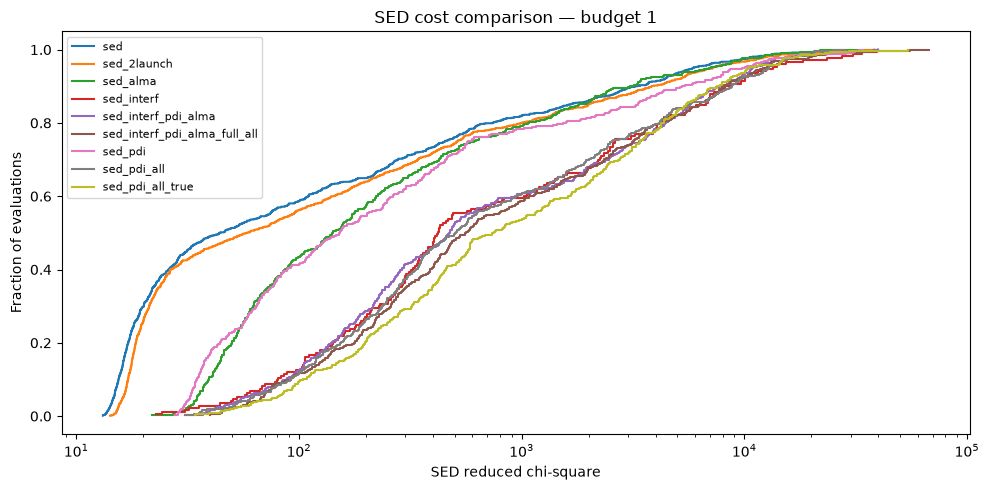

In [4]:
if not 0 < BEST_FRACTION <= 1:
    raise ValueError('BEST_FRACTION must be in (0, 1].')
sample = df[np.isclose(df['budget'], BUDGET)].copy()
if sample.empty:
    raise ValueError(f'No evaluations at budget {BUDGET}; available: {sorted(df.budget.unique())}')
if SED_COST_LIMIT is None:
    cuts = sample.groupby('run')['sed_cost'].quantile(BEST_FRACTION)
    good = sample[sample['sed_cost'] <= sample['run'].map(cuts)].copy()
    selection_label = f'Best {BEST_FRACTION:.0%} by SED cost within each run'
else:
    cuts = pd.Series(SED_COST_LIMIT, index=sorted(sample.run.unique()))
    good = sample[sample['sed_cost'] <= SED_COST_LIMIT].copy()
    selection_label = f'SED reduced chi-square <= {SED_COST_LIMIT:g}'
selection_summary = sample.groupby('run').size().rename('available').to_frame()
selection_summary['selected'] = good.groupby('run').size().reindex(selection_summary.index, fill_value=0)
selection_summary['sed_cost_cut'] = cuts
display(selection_summary)
print('Runs absent at this budget:', sorted(set(df.run) - set(sample.run)))
if good.empty:
    raise ValueError('No models pass the selected SED cost threshold.')
if SAVE_OUTPUTS:
    good.to_csv(OUTPUT / f'selected_sed_models_budget_{BUDGET:g}.csv', index=False)

fig, ax = plt.subplots(figsize=(10, 5))
for run, group in sample.groupby('run'):
    costs = np.sort(group.sed_cost)
    ax.step(costs, np.arange(1, len(costs)+1)/len(costs), where='post', label=run)
ax.set(xlabel='SED reduced chi-square', ylabel='Fraction of evaluations',
       title=f'SED cost comparison — budget {BUDGET:g}')
if (sample.sed_cost > 0).all():
    ax.set_xscale('log')
ax.legend(fontsize=8)
fig.tight_layout()
if SAVE_OUTPUTS:
    fig.savefig(OUTPUT / f'sed_costs_budget_{BUDGET:g}.png', dpi=150)
plt.show()


## Marginal distributions for every varied parameter

A common binning is used across runs. Discrete choices use frequencies rather than a smoothed density. Logarithmic parameters are displayed in log10 coordinates. Parameters that become constant after selection are still included here. Per-run quantile cuts select relative fit quality; use `SED_COST_LIMIT` for a common absolute criterion.


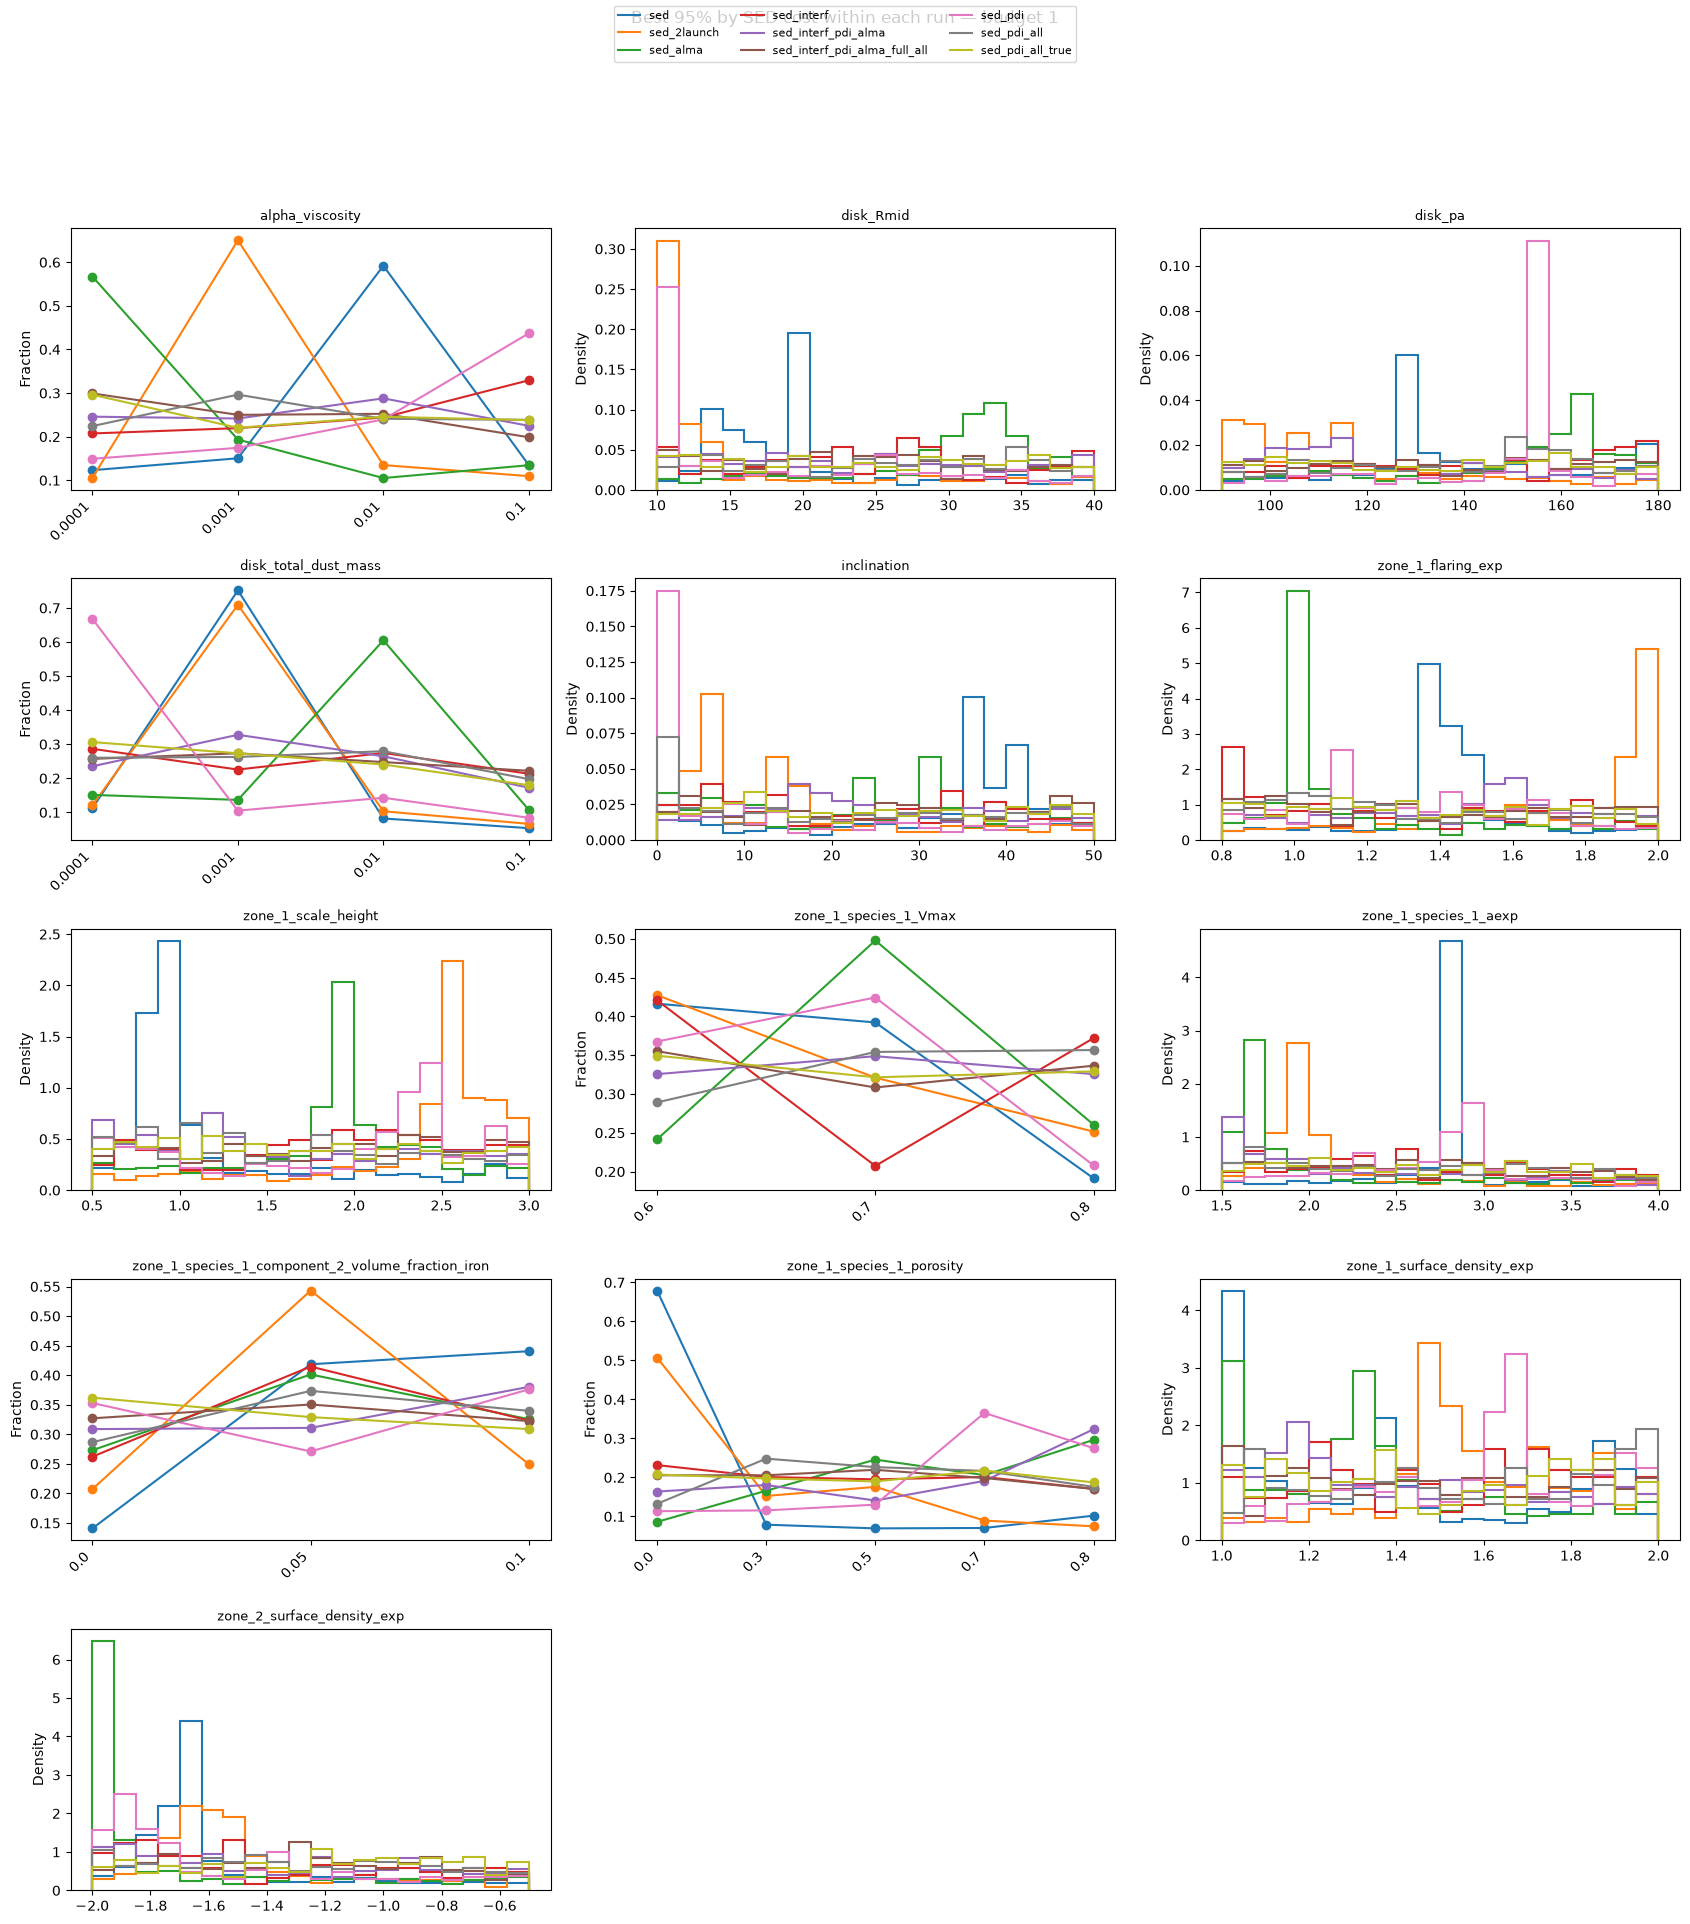

In [5]:
if not params:
    raise ValueError('No varied parameters found.')
ncols = 3
fig, axes = plt.subplots(int(np.ceil(len(params)/ncols)), ncols,
                         figsize=(17, 3.8*np.ceil(len(params)/ncols)), squeeze=False)
runs = sorted(sample.run.unique())
colors = dict(zip(runs, plt.get_cmap('tab10').colors))
for ax, p in zip(axes.flat, params):
    values = pd.to_numeric(sample[p], errors='coerce')
    numeric = values.notna().sum() == sample[p].notna().sum()
    use_log = numeric and p in LOG_PARAMETERS and (values.dropna() > 0).all()
    if numeric and values.nunique() > 12:
        transformed = np.log10(values) if use_log else values
        bins = np.linspace(transformed.min(), transformed.max(), 21)
        for run, group in good.groupby('run'):
            x = pd.to_numeric(group[p]).dropna()
            if use_log:
                x = np.log10(x)
            if len(x):
                ax.hist(x, bins=bins, density=True, histtype='step',
                        linewidth=1.5, color=colors[run], label=run)
        ax.set_ylabel('Density')
        label = f'log10({p})' if use_log else p
    else:
        categories = sorted(sample[p].dropna().unique(), key=lambda x: float(x) if numeric else str(x))
        for run, group in good.groupby('run'):
            freq = group[p].value_counts(normalize=True).reindex(categories, fill_value=0)
            ax.plot(range(len(categories)), freq, marker='o', color=colors[run], label=run)
        ax.set_xticks(range(len(categories)))
        ax.set_xticklabels(categories, rotation=45, ha='right')
        ax.set_ylabel('Fraction')
        label = p
    ax.set_title(label, fontsize=9, wrap=True)
for ax in axes.flat[len(params):]:
    ax.set_visible(False)
from matplotlib.lines import Line2D
fig.legend([Line2D([0], [0], color=colors[r]) for r in sorted(good.run.unique())],
           sorted(good.run.unique()), loc='upper center', ncol=3, fontsize=8)
fig.suptitle(f'{selection_label} — budget {BUDGET:g}', y=1.01)
fig.tight_layout(rect=(0, 0, 1, 0.93))
if SAVE_OUTPUTS:
    fig.savefig(OUTPUT / f'sed_parameter_distributions_budget_{BUDGET:g}.png', dpi=150, bbox_inches='tight')
plt.show()


## Optional corner plot

Choose a run and optionally a shorter parameter list. A full corner plot can be large. Constant parameters are reported and omitted only from the corner plot; they remain in the marginal plots above. Contours and percentile titles are disabled to avoid presenting these adaptive samples as credible regions.

Corner plots use `1 / sed_cost` weights aligned with the plotted rows. Models with zero or non-positive SED cost are omitted because inverse-cost weights are undefined there.


Omitted models with undefined inverse-cost weights: 0
Omitted constant or nonnumeric parameters: []


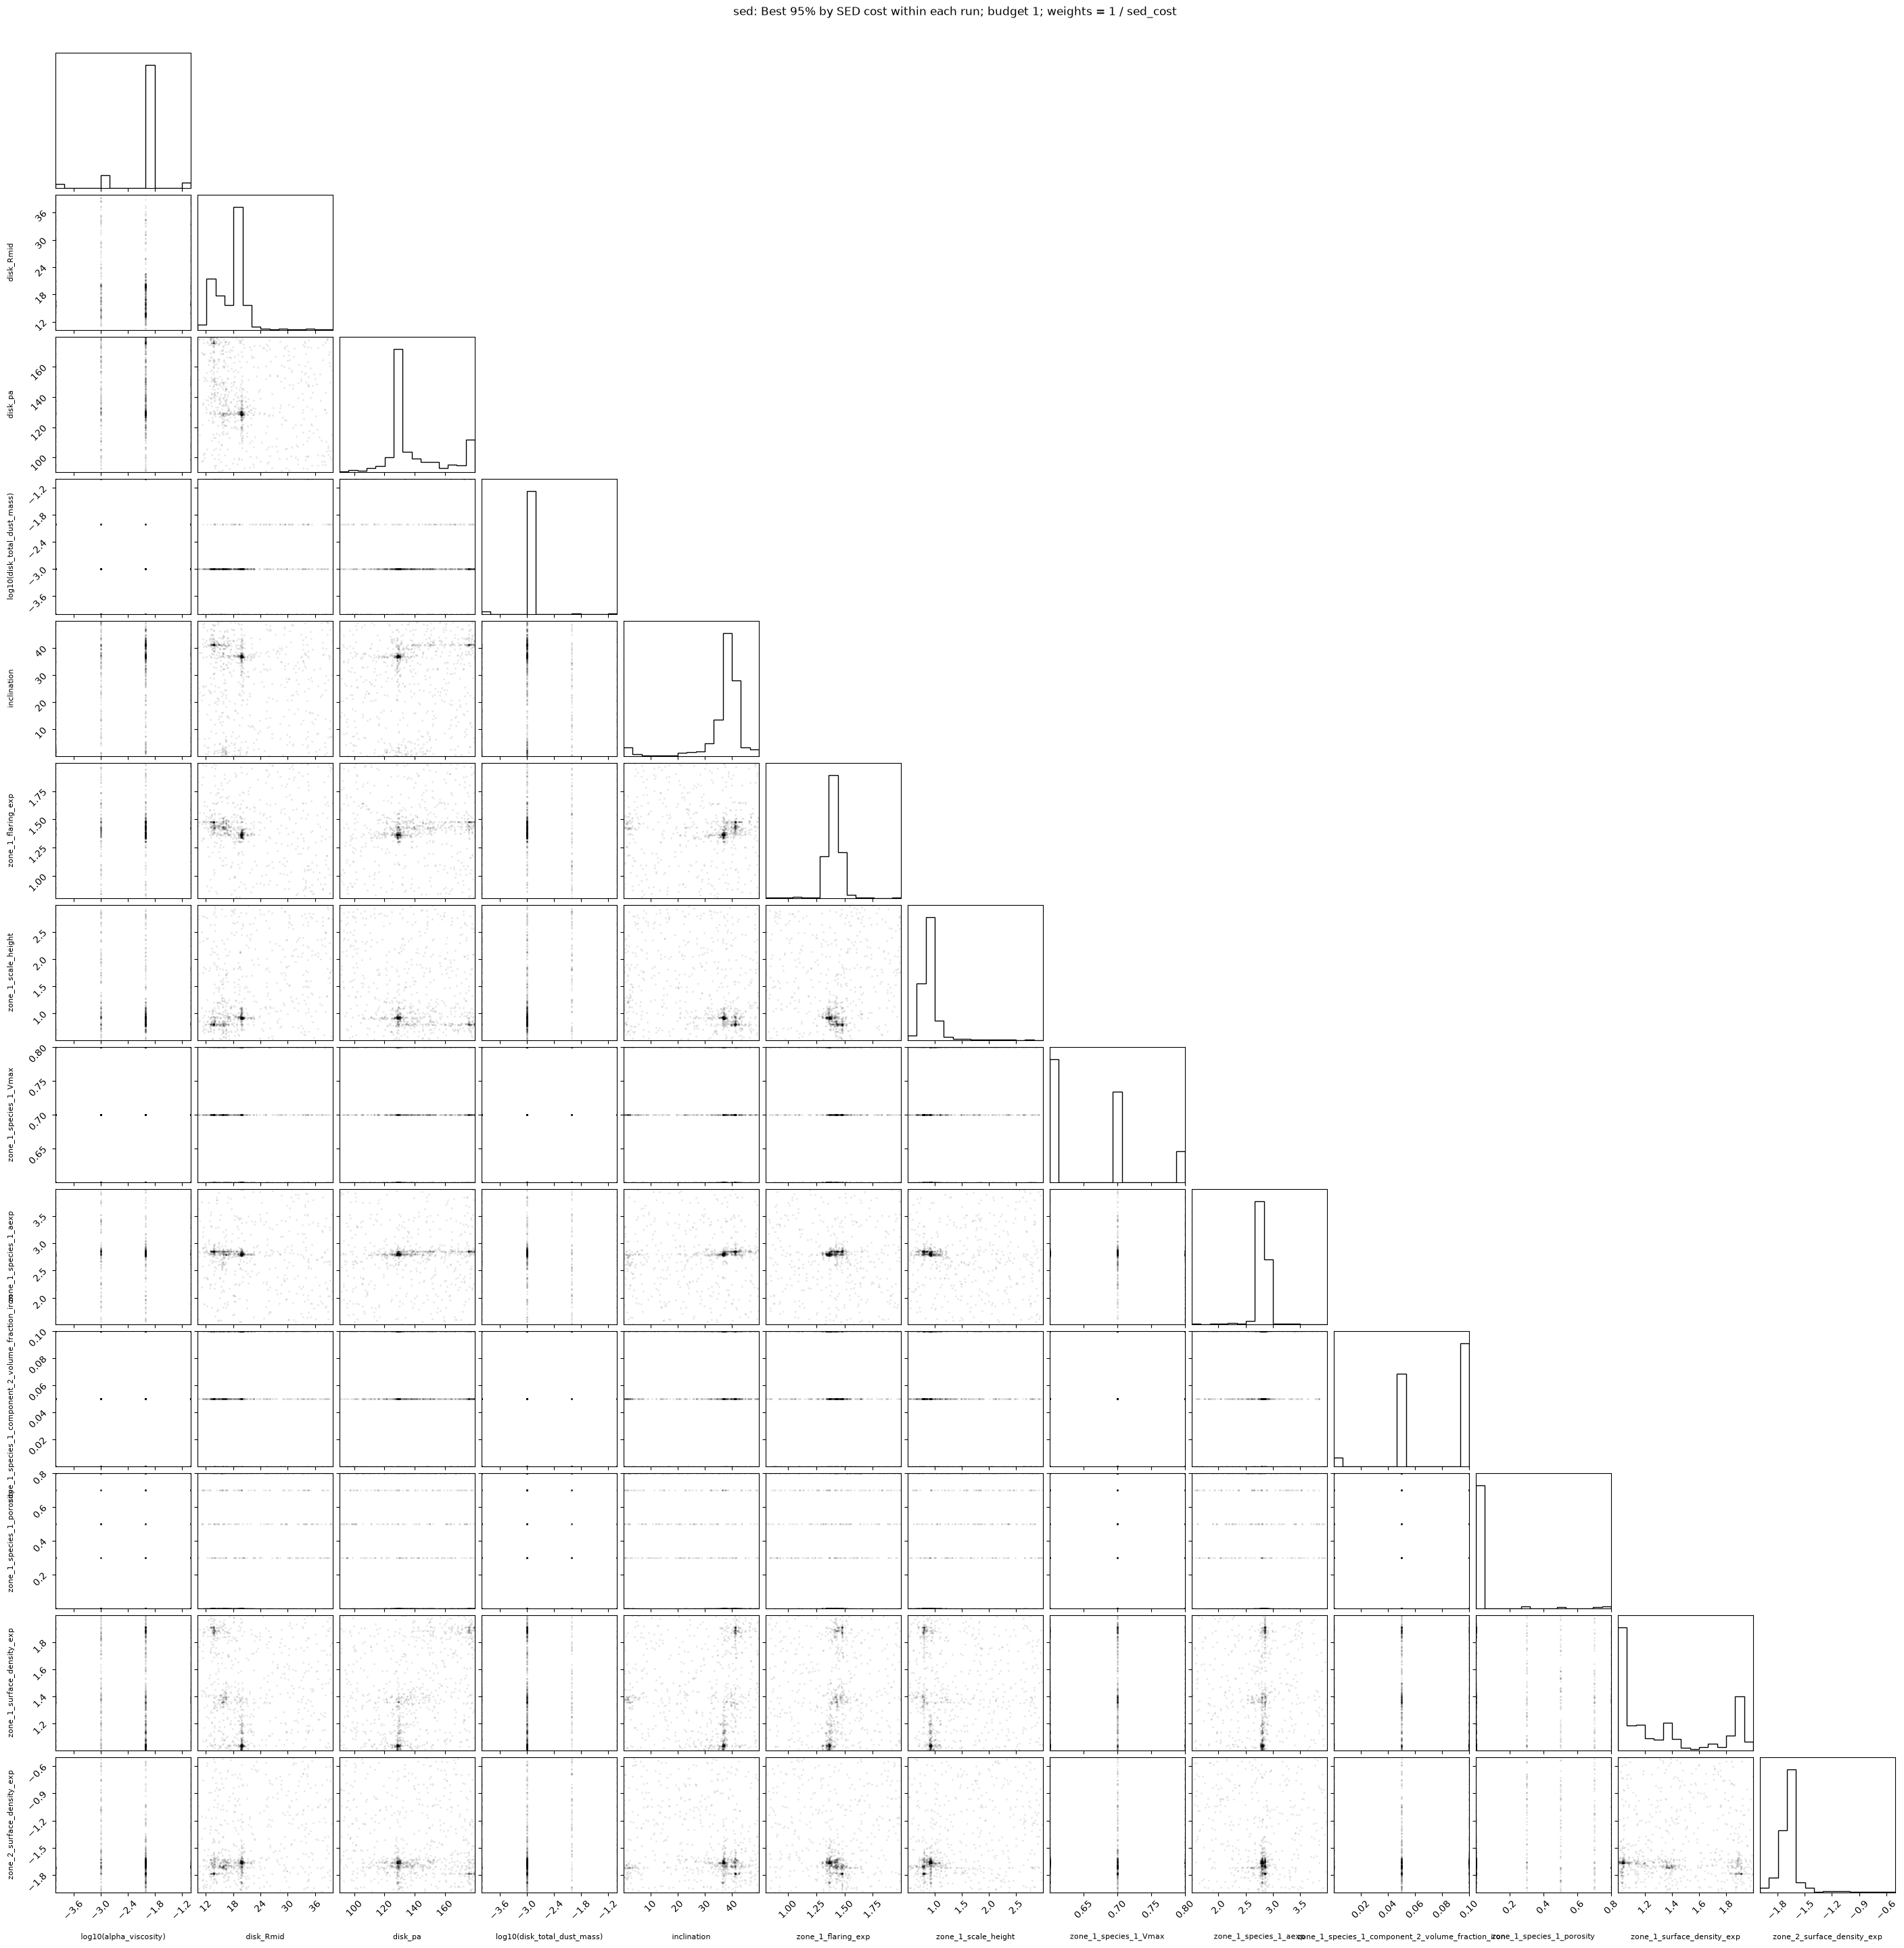

In [6]:
CORNER_RUN = 'sed'
CORNER_PARAMETERS = params  # e.g. ['disk_Rmid', 'zone_1_scale_height', 'inclination']
try:
    import corner
except ImportError:
    print('Optional corner package unavailable; marginal plots above cover all parameters.')
else:
    selected = good[good.run == CORNER_RUN].copy()
    positive_cost = np.isfinite(selected['sed_cost']) & (selected['sed_cost'] > 0)
    print('Omitted models with undefined inverse-cost weights:', int((~positive_cost).sum()))
    selected = selected.loc[positive_cost]
    data = selected[CORNER_PARAMETERS].apply(pd.to_numeric, errors='coerce')
    valid = [p for p in data if data[p].nunique() > 1]
    print('Omitted constant or nonnumeric parameters:', sorted(set(CORNER_PARAMETERS)-set(valid)))
    data = data[valid].dropna()
    if not valid or len(data) <= len(valid):
        print('Too few complete selected models for this corner plot. Increase BEST_FRACTION or choose fewer parameters.')
    else:
        labels = []
        for p in valid:
            if p in LOG_PARAMETERS and (data[p] > 0).all():
                data[p] = np.log10(data[p])
                labels.append(f'log10({p})')
            else:
                labels.append(p)
        weights = 1.0 / selected.loc[data.index, 'sed_cost'].to_numpy()
        fig = corner.corner(data.to_numpy(), labels=labels, bins=15,
                            weights=weights,
                            plot_datapoints=True, plot_density=False,
                            plot_contours=False, show_titles=False,
                            label_kwargs={'fontsize': 8})
        fig.suptitle(f'{CORNER_RUN}: {selection_label}; budget {BUDGET:g}; weights = 1 / sed_cost', y=1.01)
    
        if SAVE_OUTPUTS:
            fig.savefig(OUTPUT / f'sed_corner_{CORNER_RUN}_budget_{BUDGET:g}.png', dpi=120, bbox_inches='tight')
        
plt.show()

In [7]:

def make_corner_plot(
    df,
    params,
    *,
    budget=None,
    best_quantile=0.3,
    title=None,
    outfile="corner.png",
):

    d = df.copy()
    if budget is not None:
        d = d[d["budget"] == budget]

    d = d.dropna(subset=["cost"])
    cost_cut = d["cost"].quantile(best_quantile)
    d = d[d["cost"] <= cost_cut]
    if len(d) == 0:
        print("No data to plot after filtering by budget and cost quantile.")
        return
    params_corner = []
    for p in params:
        if p not in d.columns:
            raise ValueError(f"Parameter '{p}' not found in DataFrame columns.")
        if d[p].unique().size >= 2:
            params_corner.append(p)
        else:
            print(f"Parameter '{p}' has less than 2 unique values in the filtered DataFrame.")


    if len(params_corner) == 0:
        print("No valid parameters to plot after filtering.")
        return
    data = d[params_corner].values

    fig = corner.corner(
        data,
        labels=params_corner,
        quantiles=[0.16, 0.5, 0.84],
        weights=1.0 / d["sed_cost"].values,
        show_titles=True,
        wrap_title_quantiles=True,
        title_fmt=".3g"  
    )
    plt.suptitle(title, fontsize=14, y=1.01)
    #fig.savefig(outfile, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)




make_corner_plot(
            data.to_numpy(),
            params=labels,
            title="try"
        )

NameError: name 'df_sel' is not defined